# ДЗ №3. Классификация акустических событий (ESC-10)

**Задача:** обучить **собственную небольшую CNN** распознавать 10 типов окружающих звуков по **log-Mel-спектрограммам** и сравнить результаты **двух** экспериментов, отличающихся **ровно одним** фактором.

В ноутбуке **уже готово**: чтение и проверка набора данных, фиксированное разбиение по folds, извлечение/кэширование log-Mel, `Dataset` и `DataLoader`.  

**Ваша работа:** написать модель, цикл train/val, метрики, контрольный эксперимент, визуализацию и выводы в ячейках `TODO`.

**Не используйте** готовые аудиомодели и предобученные веса. **Наличие GPU не обязательно**: используйте небольшую сеть, не меняя установленный состав данных и число эпох. Готовый результат — один `solution.ipynb` с сохранёнными выводами ячеек.

## 1. Подготовка среды и скачивание данных

1. Скачайте полный архив [ESC-50 с официального GitHub](https://github.com/karolpiczak/ESC-50/archive/refs/heads/master.zip) (около **600 МБ**). Он содержит также нужное нам подмножество **ESC-10** — 400 пятисекундных WAV-записей.
2. Распакуйте архив **в `data/` рядом с `solution.ipynb`**, сохраняя структуру каталогов:

   ```text
   ваша_папка/
   ├── solution.ipynb
   ├── data/
   │   └── ESC-50-master/
   │       ├── audio/           # 2000 файлов .wav
   │       └── meta/
   │           └── esc50.csv    # содержит признак esc10
   ```

   В Windows можно открыть скачанный ZIP в Проводнике и распаковать папку `ESC-50-master` внутрь `data/`. В Linux/macOS: `unzip ESC-50-master.zip -d data` из каталога с ноутбуком.

3. Установите зависимости **один раз** в том же окружении, где запускается Jupyter:

   ```bash
   python -m pip install -r requirements.txt
   ```

   Если файла `requirements.txt` нет, выполните `python -m pip install torch numpy pandas "librosa>=0.10.2" soundfile matplotlib scikit-learn ipython`.

4. Запустите ячейки ниже: код **сам выберет** 400 записей ESC-10 по `esc10 == True`. В первую обработку лог-Mel будет создан кэш в `data/`, чтобы избежать повторных вычислений. При изменении настроек признаки нужно пересоздать, но **в этой работе параметры менять нельзя**.

**Внимание:** не скачивайте отдельную старую версию ESC-10 в другом формате: этот ноутбук рассчитан на структуру официального репозитория ESC-50 с `.wav` и `meta/esc50.csv`.

## 2. Импорты и фиксированные настройки

In [1]:
from pathlib import Path
import random

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import Audio, display
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
SAMPLE_RATE = 16_000
DURATION_S = 5
N_MELS = 64
N_FFT = 1024
HOP_LENGTH = 256
BATCH_SIZE = 16
MIN_EPOCHS = 8
TRAIN_FOLDS = (1, 2, 3, 4)
VAL_FOLD = 5
NUM_CLASSES = 10
NUM_WORKERS = 0  # Надёжно работает и в Jupyter на Windows
DATA_DIR = Path('data')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def set_random_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Для гарантированной bitwise-воспроизводимости на GPU могут потребоваться
    # дополнительные настройки backend / deterministic algorithms.


set_random_seeds(SEED)
print('PyTorch:', torch.__version__, '| librosa:', librosa.__version__, '| device:', DEVICE)

PyTorch: 2.15.0+cpu | librosa: 0.11.0 | device: cpu


## 3. Метаданные и фиксированное разбиение

Ищем `meta/esc50.csv` внутри `data/`, выбираем строки с `esc10 == True`, строим **собственную последовательную нумерацию меток 0…9**. Нельзя использовать исходный столбец `target` как метку задачи ESC-10: в полном ESC-50 его значения находятся в диапазоне 0…49.

**Обязательные размеры:** всего 400 записей, 10 классов, по 40 записей на класс. Обучение — folds 1–4 (320 файлов, 32 на класс); валидация — fold 5 (80 файлов, 8 на класс). Состав данных **не менять**.

In [2]:
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f'Нет {DATA_DIR.resolve()}. Скачайте ESC-50 и распакуйте папку ESC-50-master в data/.'
    )

candidates = sorted(DATA_DIR.rglob('esc50.csv'))
candidates = [p for p in candidates if p.parent.name == 'meta' and (p.parent.parent / 'audio').is_dir()]
if not candidates:
    raise FileNotFoundError(
        'В data/ не найдены meta/esc50.csv и соседняя папка audio/. '
        'Проверьте структуру полного архива ESC-50.'
    )
if len(candidates) > 1:
    raise RuntimeError(f'Найдено несколько копий датасета: {candidates}. Оставьте одну.')

META_CSV = candidates[0]
AUDIO_DIR = META_CSV.parent.parent / 'audio'
meta = pd.read_csv(META_CSV)
meta['esc10'] = meta['esc10'].astype(str).str.lower().eq('true')
esc10_df = meta.loc[meta['esc10']].copy()
label_names = sorted(esc10_df['category'].unique().tolist())
label_to_idx = {name: i for i, name in enumerate(label_names)}
esc10_df['label'] = esc10_df['category'].map(label_to_idx).astype(int)
esc10_df = esc10_df.sort_values(['fold', 'filename']).reset_index(drop=True)

assert len(esc10_df) == 400, f'Ожидается 400 записей, получено {len(esc10_df)}'
assert len(label_names) == NUM_CLASSES
assert esc10_df.groupby('category').size().eq(40).all()
assert set(esc10_df['fold'].unique()) == {1, 2, 3, 4, 5}
assert esc10_df.groupby(['fold', 'category']).size().eq(8).all()

missing_files = [name for name in esc10_df['filename'] if not (AUDIO_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        f'Не найдены {len(missing_files)} WAV-файлов ESC-10. Первый: {missing_files[0]}. '
        'Нужно распаковать полный архив, а не только метаданные.'
    )

train_mask = esc10_df['fold'].isin(TRAIN_FOLDS).to_numpy()
val_mask = esc10_df['fold'].eq(VAL_FOLD).to_numpy()
train_idx = np.flatnonzero(train_mask)
val_idx = np.flatnonzero(val_mask)
assert len(train_idx) == 320 and len(val_idx) == 80
assert set(train_idx).isdisjoint(set(val_idx))

print('Метаданные:', META_CSV)
print('Количество файлов: train =', len(train_idx), '| val =', len(val_idx))
print('Классы (индекс → имя):')
print(pd.DataFrame({'label': list(range(NUM_CLASSES)), 'class': label_names}).to_string(index=False))
print('\nПроверка классов по folds:')
display(pd.crosstab(esc10_df['category'], esc10_df['fold']))

Метаданные: data\ESC-50-master\meta\esc50.csv
Количество файлов: train = 320 | val = 80
Классы (индекс → имя):
 label          class
     0       chainsaw
     1     clock_tick
     2 crackling_fire
     3    crying_baby
     4            dog
     5     helicopter
     6           rain
     7        rooster
     8      sea_waves
     9       sneezing

Проверка классов по folds:


fold,1,2,3,4,5
category,,,,,
chainsaw,8,8,8,8,8
clock_tick,8,8,8,8,8
crackling_fire,8,8,8,8,8
crying_baby,8,8,8,8,8
dog,8,8,8,8,8
helicopter,8,8,8,8,8
rain,8,8,8,8,8
rooster,8,8,8,8,8
sea_waves,8,8,8,8,8


## 4. Послушаем и рассмотрим записи

Выведите три фрагмента **разных классов**: запись для воспроизведения, её волновую форму и log-Mel-спектрограмму. **TODO для отчёта:** в текстовой ячейке после графиков кратко опишите, чем различаются эти звуки по длительности, ритму, частотам или характеру шума.

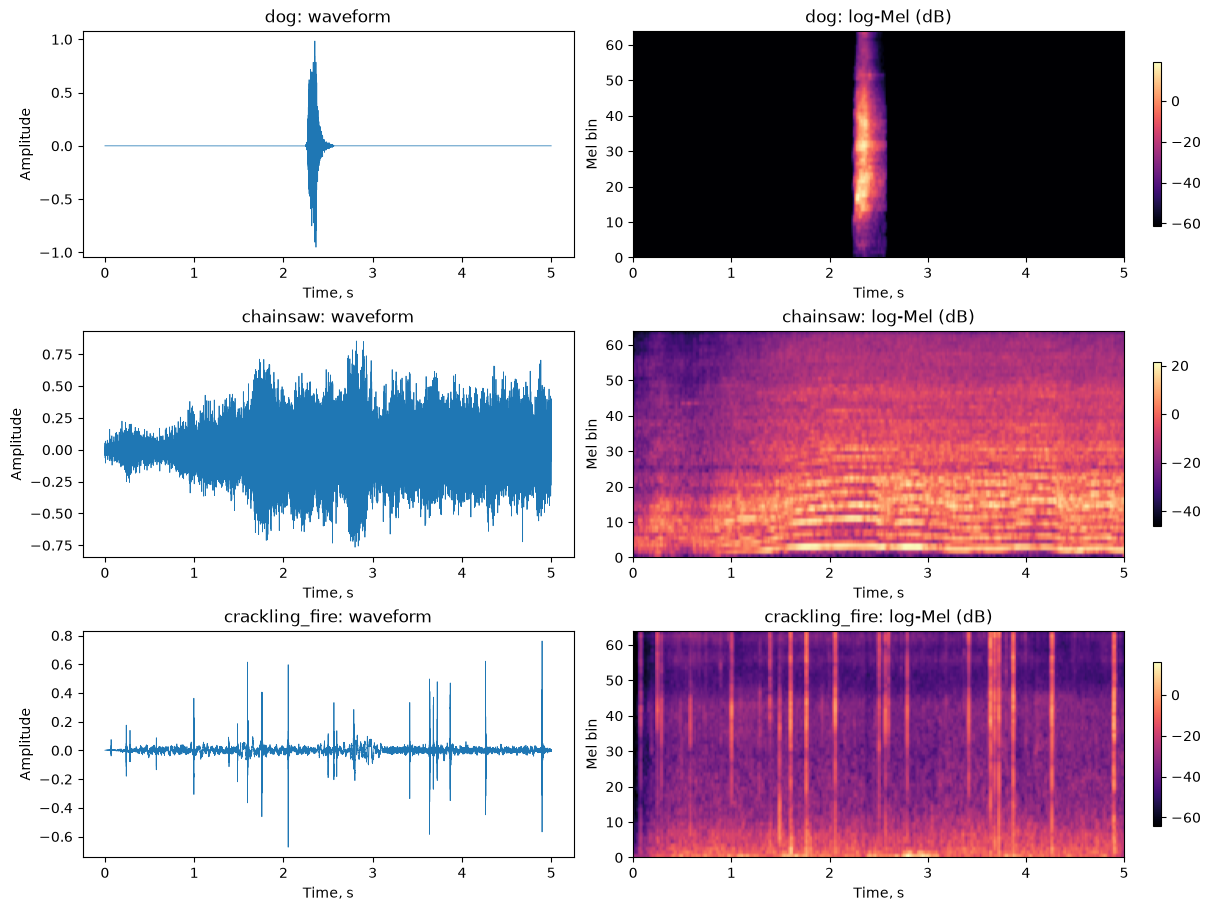

Пример: dog | 1-100032-A-0.wav


Пример: chainsaw | 1-116765-A-41.wav


Пример: crackling_fire | 1-17150-A-12.wav


In [4]:
def read_waveform(filename: str) -> np.ndarray:
    """Mono float32 и ресемплинг до заданной частоты."""
    waveform, native_sr = sf.read(AUDIO_DIR / filename, dtype='float32')
    if waveform.ndim == 2:
        waveform = waveform.mean(axis=1)
    if native_sr != SAMPLE_RATE:
        waveform = librosa.resample(waveform, orig_sr=native_sr, target_sr=SAMPLE_RATE)
    expected = int(SAMPLE_RATE * DURATION_S)
    # WAV обычно имеет нужную длину, pad/truncate страхует от единичных отсчётов.
    if len(waveform) < expected:
        waveform = np.pad(waveform, (0, expected - len(waveform)))
    else:
        waveform = waveform[:expected]
    return waveform.astype(np.float32, copy=False)


def waveform_to_logmel(waveform: np.ndarray) -> np.ndarray:
    mel_power = librosa.feature.melspectrogram(
        y=waveform, sr=SAMPLE_RATE, n_fft=N_FFT,
        hop_length=HOP_LENGTH, n_mels=N_MELS, power=2.0,
    )
    logmel = librosa.power_to_db(mel_power, ref=1.0, top_db=80.0)
    return logmel.astype(np.float32)

selected_examples = esc10_df.drop_duplicates('category').iloc[:3]
fig, axes = plt.subplots(3, 2, figsize=(12, 9), constrained_layout=True)
for i, row in enumerate(selected_examples.itertuples()):
    wav = read_waveform(row.filename)
    spec = waveform_to_logmel(wav)
    axes[i, 0].plot(np.arange(len(wav)) / SAMPLE_RATE, wav, linewidth=0.55)
    axes[i, 0].set(title=f'{row.category}: waveform', xlabel='Time, s', ylabel='Amplitude')
    im = axes[i, 1].imshow(spec, origin='lower', aspect='auto', cmap='magma',
                           extent=(0, DURATION_S, 0, N_MELS))
    axes[i, 1].set(title=f'{row.category}: log-Mel (dB)', xlabel='Time, s', ylabel='Mel bin')
    fig.colorbar(im, ax=axes[i, 1], shrink=0.72)
plt.show()
for row in selected_examples.itertuples():
    print('Пример:', row.category, '|', row.filename)
    display(Audio(data=read_waveform(row.filename), rate=SAMPLE_RATE))

**TODO (ваш текст):** сравните три записи по наблюдаемым особенностям волновой формы и спектрограммы.

**Сравнение трёх записей (dog, chainsaw, crackling_fire):**

- **dog** (`1-100032-A-0.wav`): почти полная тишина все 5 секунд и **один короткий лай**. На волновой форме — одиночный резкий всплеск амплитуды (до ±1.0), на log-Mel — узкая по времени **вертикальная полоса энергии**, размазанная почти по всем mel-каналам (широкополосный импульс), ярче в нижне-средних частотах. Остальное время фон чёрный (≈ −60 дБ и ниже).

- **chainsaw** (`1-116765-A-41.wav`): **непрерывный стационарный рёв мотора** без пауз. Волна — плотная «трава»: амплитуда нарастает примерно к 1.5–2 с (разгон пилы) и дальше держится на уровне ±0.5–0.75. На спектрограмме энергия присутствует **во всех 64 каналах всё время**: в нижних каналах видны устойчивые **горизонтальные полосы-гармоники** двигателя, верхние каналы заполнены широкополосным шумом.

- **crackling_fire** (`1-17150-A-12.wav`): **тихий шумовой фон + случайные щелчки** потрескивания. На спектрограмме — широкополосный фон и **множество тонких вертикальных линий-щелчков**, случайно разбросанных по времени, плюс яркая низкочастотная полоса у самого низа (гул горения).

**Главное различие:** классы отличаются прежде всего *временной структурой* — одиночный импульс на тишине (dog), непрерывный гул с гармониками (chainsaw), случайные импульсы на шумовом фоне (crackling_fire) — и *частотным составом* (тональные НЧ-гармоники против широкополосного шума). Свёртки CNN выделяют именно такие локальные паттерны «частота × время»: вертикальные импульсы, горизонтальные гармоники и плотность щелчков.

## 5. Подготовка и кэширование log-Mel-признаков

Все записи преобразуем одинаково: 5 секунд при 16 кГц → **64 Mel-канала**, `n_fft=1024`, `hop_length=256`. На диске будет создан небольшой кэш с признаками. Его **можно удалить** — ноутбук пересчитает признаки. При двух запусках CNN кэш позволяет не декодировать WAV повторно.

In [5]:
CACHE_FILE = DATA_DIR / 'esc10_logmel_sr16000_mel64_fft1024_hop256_v1.npz'
expected_filenames = esc10_df['filename'].to_numpy(dtype=str)

if CACHE_FILE.is_file():
    with np.load(CACHE_FILE) as cached:
        cached_names = cached['filenames'].astype(str)
        if not np.array_equal(cached_names, expected_filenames):
            raise RuntimeError('Кэш создан для другого состава/порядка файлов. Удалите ' + str(CACHE_FILE))
        X_logmel = cached['features'].astype(np.float32)
    print('Прочитан кэш:', CACHE_FILE)
else:
    features = []
    print(f'Подготовка {len(esc10_df)} записей. Выполняется только при первом запуске…')
    for n, filename in enumerate(expected_filenames, start=1):
        features.append(waveform_to_logmel(read_waveform(filename)))
        if n % 100 == 0:
            print(f'Обработано {n}/{len(expected_filenames)}')
    X_logmel = np.stack(features, axis=0).astype(np.float32)
    np.savez_compressed(CACHE_FILE, features=X_logmel, filenames=expected_filenames)
    print('Сохранён кэш:', CACHE_FILE)

expected_frames = 1 + (SAMPLE_RATE * DURATION_S) // HOP_LENGTH
assert X_logmel.shape == (400, N_MELS, expected_frames), X_logmel.shape
assert np.isfinite(X_logmel).all(), 'В спектрограммах обнаружены NaN/Inf'
print('Форма признаков [N, Mel, T]:', X_logmel.shape)

Подготовка 400 записей. Выполняется только при первом запуске…
Обработано 100/400
Обработано 200/400
Обработано 300/400
Обработано 400/400
Сохранён кэш: data\esc10_logmel_sr16000_mel64_fft1024_hop256_v1.npz
Форма признаков [N, Mel, T]: (400, 64, 313)


## 6. Нормализация, `Dataset` и `DataLoader`

Среднее и стандартное отклонение считаем **только на обучении** (folds 1–4) и применяем эти же числа к валидации. Иначе произошла бы небольшая **утечка информации из val**. При каждом новом эксперименте используйте `make_dataloaders(SEED)` для одинаковой перестановки train-примеров.

In [6]:
train_mean = float(X_logmel[train_idx].mean())
train_std = float(X_logmel[train_idx].std())
assert train_std > 1e-6
X_normalized = ((X_logmel - train_mean) / train_std)[:, np.newaxis, :, :].astype(np.float32)
y_all = esc10_df['label'].to_numpy(dtype=np.int64)


class ESC10Dataset(Dataset):
    def __init__(self, indices):
        self.indices = np.asarray(indices, dtype=np.int64)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        global_index = int(self.indices[index])
        spectrogram = torch.from_numpy(X_normalized[global_index])  # [1, 64, T], float32
        label = torch.tensor(y_all[global_index], dtype=torch.long)
        return spectrogram, label


train_dataset = ESC10Dataset(train_idx)
val_dataset = ESC10Dataset(val_idx)


def make_dataloaders(seed=SEED):
    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(seed),
        num_workers=NUM_WORKERS,
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
    )
    return train_loader, val_loader


train_loader, val_loader = make_dataloaders(SEED)
inputs, targets = next(iter(train_loader))
print('Batch inputs:', tuple(inputs.shape), inputs.dtype)
print('Batch targets:', tuple(targets.shape), targets.dtype)
print('Normalization (train only): mean=', round(train_mean, 3), 'std=', round(train_std, 3))
assert inputs.shape == (BATCH_SIZE, 1, N_MELS, expected_frames)
assert targets.dtype == torch.long and targets.min() >= 0 and targets.max() < NUM_CLASSES
assert len(train_dataset) == 320 and len(val_dataset) == 80

Batch inputs: (16, 1, 64, 313) torch.float32
Batch targets: (16,) torch.int64
Normalization (train only): mean= -28.936 std= 22.035


## 7. Самостоятельная реализация CNN — `TODO`

Напишите **свою компактную сеть**, используя только базовые слои PyTorch. Можно использовать `Conv2d`, `ReLU`, `MaxPool2d`, `AdaptiveAvgPool2d`, `Flatten`, `Linear`, `Dropout`, `BatchNorm2d`. Это примеры допустимых компонентов.

**Формат входных и выходных данных:** вход `[B, 1, 64, 313]` -> **логиты** `[B, 10]` (без `softmax`). Для обучения на CPU начинайте с небольшого числа каналов и глобального усреднения в конце.

**TODO:** напишите архитектуру и в следующей текстовой ячейке кратко объясните, как меняется форма тензора.

In [ ]:
class AudioCNN(nn.Module):
    """Компактная CNN: [B, 1, 64, 313] -> логиты [B, 10]."""

    def __init__(self, num_classes=NUM_CLASSES, dropout_p=0.0):
        super().__init__()
        self.features = nn.Sequential(
            # блок 1: [B,1,64,313] -> [B,16,32,156]
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            # блок 2: -> [B,32,16,78]
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            # блок 3: -> [B,64,8,39]
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.gap = nn.AdaptiveAvgPool2d((1, 1))   # глобальный pooling -> [B,64,1,1]
        self.head = nn.Sequential(
            nn.Flatten(),                          # [B,64]
            nn.Dropout(p=dropout_p),               # 0.0 в базовом, 0.3 во втором
            nn.Linear(64, num_classes),            # логиты, без softmax
        )

    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        return self.head(x)


def check_model_output_shape(model: nn.Module, input_batch: torch.Tensor):
    model = model.to(DEVICE).eval()
    with torch.no_grad():
        logits = model(input_batch.to(DEVICE))
    expected = (len(input_batch), NUM_CLASSES)
    assert tuple(logits.shape) == expected, (tuple(logits.shape), expected)
    assert torch.isfinite(logits).all()
    print('Проверка формы модели пройдена:', tuple(logits.shape))


set_random_seeds(SEED)
model = AudioCNN()
check_model_output_shape(model, inputs)
print('Обучаемых параметров:', sum(p.numel() for p in model.parameters() if p.requires_grad))

Проверка формы модели пройдена: (16, 10)
Обучаемых параметров: 24170


**TODO (ваш текст):** слои и размеры активаций в вашей CNN, число обучаемых параметров, почему модель подходит для CPU.

**Архитектура.** Три свёрточных блока `Conv2d(3×3, padding=1) → BatchNorm2d → ReLU → MaxPool2d(2×2)`, каналы 1→16→32→64. Форма тензора меняется так:

`[1, 64, 313] → [16, 32, 156] → [32, 16, 78] → [64, 8, 39]`

(каждый MaxPool уменьшает частоту и время вдвое). Затем `AdaptiveAvgPool2d(1,1)` — глобальный average pooling: каждая из 64 карт признаков усредняется в одно число → вектор `[64]`. Голова: `Flatten → Dropout(p) → Linear(64→10)` выдаёт **логиты без softmax** (softmax внутри CrossEntropyLoss при обучении).

**Почему подходит для CPU:** всего **24 170 обучаемых параметров**; глобальный pooling вместо большого полносвязного слоя убирает миллионы параметров, которые были бы при Flatten всей карты `[64, 8, 39]`. BatchNorm стабилизирует и ускоряет сходимость, ReLU — нелинейность, свёртки 3×3 ловят локальные паттерны «частота × время». Dropout вынесен в голову и управляется параметром `dropout_p`, чтобы во втором эксперименте менять только его вероятность, не трогая архитектуру.

## 8. Метрики классификации — `TODO`

Собирайте предсказания модели для **всех 80** примеров из `val`, а не вычисляйте среднее значение метрики по батчам». Зафиксируйте:

- `val accuracy` — доля верных классов;
- `val macro-F1` — среднее F1 по 10 классам с равными весами;
- `val loss` — средняя потеря по примерам;
- `confusion_matrix` — матрица ошибок с подписанными классами.

Используйте `sklearn.metrics` с `labels=list(range(NUM_CLASSES))` и `zero_division=0` для расчёта macro-F1. Метрики рассчитываются по предсказанным меткам `argmax(logits, dim=1)`.

`CrossEntropyLoss` принимает именно **логиты** `[B, 10]` и метки `torch.long` `[B]`. Вызывать `softmax` перед ней **не нужно**.

In [8]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    """Полный проход по val: loss, accuracy, macro-F1 + предсказания по всем 80 записям."""
    model.eval()
    total_loss, n = 0.0, 0
    y_true, y_pred, probs = [], [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        loss = criterion(logits, yb)
        total_loss += loss.item() * len(yb)   # взвешиваем по размеру батча
        n += len(yb)
        y_true.append(yb.cpu().numpy())
        y_pred.append(logits.argmax(dim=1).cpu().numpy())
        probs.append(torch.softmax(logits, dim=1).cpu().numpy())
    y_true = np.concatenate(y_true)
    y_pred = np.concatenate(y_pred)
    probs = np.concatenate(probs)
    return {
        'loss': total_loss / n,
        'accuracy': accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                             average='macro', zero_division=0),
        'y_true': y_true, 'y_pred': y_pred, 'probs': probs,
    }

## 9. Обучение базовой CNN — `TODO`

1. Вызовите `set_random_seeds(SEED)` **до** создания модели и оптимизатора.
2. Вызовите `make_dataloaders(SEED)`, обучайте **не менее 8 эпох**.
3. На train обновляйте веса: `optimizer.zero_grad()` → `loss.backward()` → `optimizer.step()`.
4. На val используйте `model.eval()` и `with torch.no_grad():`, не обновляйте веса.
5. Сохраняйте `train_loss`, `val_loss`, `val_accuracy`, `val_macro_f1` **после каждой эпохи**.

При вычислении средней потери по эпохе учитывайте размеры батчей: суммируйте `loss.item() * batch_size`, затем делите на количество примеров, а не на число батчей (если размер последнего батча отличается).

In [9]:
EPOCHS = 15            # >= MIN_EPOCHS (8)
LEARNING_RATE = 1e-3

def train_model(model, train_loader, val_loader, epochs=EPOCHS, lr=LEARNING_RATE, run_name='run'):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()           # принимает логиты [B,10] и метки long [B]
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'val_accuracy': [], 'val_macro_f1': []}
    w0 = next(model.parameters()).detach().clone()   # снимок весов до обучения

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, n = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(yb)
            n += len(yb)
        train_loss = total_loss / n
        val = evaluate(model, val_loader, criterion)   # eval + no_grad, веса не трогаем
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val['loss'])
        history['val_accuracy'].append(val['accuracy'])
        history['val_macro_f1'].append(val['macro_f1'])
        print(f'[{run_name}] epoch {epoch:2d}/{epochs} | train loss {train_loss:.4f} | '
              f'val loss {val["loss"]:.4f} | val acc {val["accuracy"]:.3f} | '
              f'val macro-F1 {val["macro_f1"]:.3f}')

    # проверки из задания (K3): веса изменились, train loss в целом убывает
    assert not torch.allclose(w0, next(model.parameters()).detach()), 'Параметры не изменились!'
    assert history['train_loss'][-1] < history['train_loss'][0], 'train loss не убывает!'
    return model, history, criterion


# ===== Базовый эксперимент: dropout p = 0.0 =====
print(f'Конфигурация: SEED={SEED}, BATCH_SIZE={BATCH_SIZE}, EPOCHS={EPOCHS}, '
      f'LR={LEARNING_RATE}, optimizer=Adam, dropout_p=0.0')
set_random_seeds(SEED)                      # seed ДО создания модели и оптимизатора
train_loader, val_loader = make_dataloaders(SEED)
model_baseline = AudioCNN(dropout_p=0.0)
model_baseline, history_baseline, criterion = train_model(
    model_baseline, train_loader, val_loader, run_name='baseline')
assert len(history_baseline['train_loss']) >= MIN_EPOCHS

val_baseline = evaluate(model_baseline, val_loader, criterion)   # финальные предсказания на всех 80
print('Базовая модель: val accuracy =', round(val_baseline['accuracy'], 3),
      '| val macro-F1 =', round(val_baseline['macro_f1'], 3))

Конфигурация: SEED=42, BATCH_SIZE=16, EPOCHS=15, LR=0.001, optimizer=Adam, dropout_p=0.0
[baseline] epoch  1/15 | train loss 1.9780 | val loss 2.0700 | val acc 0.287 | val macro-F1 0.157
[baseline] epoch  2/15 | train loss 1.6506 | val loss 1.7748 | val acc 0.412 | val macro-F1 0.345
[baseline] epoch  3/15 | train loss 1.4938 | val loss 1.5065 | val acc 0.475 | val macro-F1 0.396
[baseline] epoch  4/15 | train loss 1.3653 | val loss 1.3394 | val acc 0.613 | val macro-F1 0.567
[baseline] epoch  5/15 | train loss 1.2657 | val loss 1.3090 | val acc 0.675 | val macro-F1 0.660
[baseline] epoch  6/15 | train loss 1.1854 | val loss 1.1240 | val acc 0.762 | val macro-F1 0.734
[baseline] epoch  7/15 | train loss 1.1358 | val loss 1.1069 | val acc 0.750 | val macro-F1 0.743
[baseline] epoch  8/15 | train loss 1.0442 | val loss 1.0179 | val acc 0.662 | val macro-F1 0.624
[baseline] epoch  9/15 | train loss 1.0215 | val loss 1.0156 | val acc 0.725 | val macro-F1 0.718
[baseline] epoch 10/15 | trai

## 10. Контролируемый эксперимент — `TODO`

Сформулируйте гипотезу **до запуска**. Измените **одну** настройку: например, только learning rate, только вероятность dropout либо только аугментацию *обучающих* спектрограмм. Состав `train/val` и базовая архитектура должны оставаться прежними.

Снова выполните `set_random_seeds(SEED)`, создайте **новую** модель и новые загрузчики. Для обоих запусков используйте не менее **8 эпох** и сравнимые вычислительные ресурсы. Изменение итоговой метрики может быть любым — важно корректное сравнение.

**Гипотеза.** Обучающих записей всего 320 (по 32 на класс), поэтому сеть быстро запоминает train и переобучается: train loss заметно ниже val loss. Dropout с p=0.3 перед классификатором случайно «выключает» 30% признаков на каждом шаге обучения и мешает запоминанию конкретных примеров.

**Ожидание:** train loss станет выше, разрыв train/val уменьшится, val macro-F1 вырастет или хотя бы не упадёт.

**Меняется ровно один фактор:** `dropout_p: 0.0 → 0.3`. Архитектура, SEED=42, файлы и folds, BATCH_SIZE=16, Adam, lr=1e-3, 15 эпох — одинаковые в обоих запусках. У Dropout нет обучаемых параметров, поэтому при том же seed обе модели стартуют с одинаковых весов.

In [10]:
DROPOUT_EXPERIMENT = 0.3

print(f'Конфигурация: SEED={SEED}, BATCH_SIZE={BATCH_SIZE}, EPOCHS={EPOCHS}, '
      f'LR={LEARNING_RATE}, optimizer=Adam, dropout_p={DROPOUT_EXPERIMENT}')
set_random_seeds(SEED)                      # та же инициализация, что у базовой модели
train_loader_exp, val_loader_exp = make_dataloaders(SEED)
model_experiment = AudioCNN(dropout_p=DROPOUT_EXPERIMENT)   # та же архитектура, другой только p
model_experiment, history_experiment, criterion_exp = train_model(
    model_experiment, train_loader_exp, val_loader_exp, run_name='dropout=0.3')
assert len(history_experiment['train_loss']) >= MIN_EPOCHS

val_experiment = evaluate(model_experiment, val_loader_exp, criterion_exp)
print('Эксперимент: val accuracy =', round(val_experiment['accuracy'], 3),
      '| val macro-F1 =', round(val_experiment['macro_f1'], 3))

Конфигурация: SEED=42, BATCH_SIZE=16, EPOCHS=15, LR=0.001, optimizer=Adam, dropout_p=0.3
[dropout=0.3] epoch  1/15 | train loss 2.0521 | val loss 2.0598 | val acc 0.263 | val macro-F1 0.143
[dropout=0.3] epoch  2/15 | train loss 1.7164 | val loss 1.8088 | val acc 0.375 | val macro-F1 0.304
[dropout=0.3] epoch  3/15 | train loss 1.5697 | val loss 1.5789 | val acc 0.537 | val macro-F1 0.454
[dropout=0.3] epoch  4/15 | train loss 1.4317 | val loss 1.3891 | val acc 0.588 | val macro-F1 0.534
[dropout=0.3] epoch  5/15 | train loss 1.3555 | val loss 1.3149 | val acc 0.650 | val macro-F1 0.633
[dropout=0.3] epoch  6/15 | train loss 1.2845 | val loss 1.1797 | val acc 0.713 | val macro-F1 0.674
[dropout=0.3] epoch  7/15 | train loss 1.2289 | val loss 1.1695 | val acc 0.688 | val macro-F1 0.677
[dropout=0.3] epoch  8/15 | train loss 1.1697 | val loss 1.0569 | val acc 0.700 | val macro-F1 0.695
[dropout=0.3] epoch  9/15 | train loss 1.1117 | val loss 1.0422 | val acc 0.762 | val macro-F1 0.745
[d

## 11. Сравнение, матрица ошибок и анализ — `TODO`

Представьте в конце ноутбука:

1. Графики `train_loss`, `val_loss`, `val_accuracy`, `val_macro_f1` по эпохам **для обоих запусков**.
2. Матрицу ошибок базовой модели на **всех 80** записях из `val`, с подписями классов.
3. Не менее **трёх** валидационных звуков с истинным и предсказанным классами. Для каждого можно воспроизвести аудио и посмотреть спектрограмму. Разберите минимум **одну** ошибку; если ошибок нет, выберите случай с минимальной уверенностью модели.
4. Сравнительную таблицу по образцу ниже и короткий вывод по гипотезе.

| Запуск | Изменённый фактор | Эпох | LR | Train loss | Val loss | Val accuracy | Val macro-F1 |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| Базовый | — | | | | | | |
| Контрольный | | | | | | | |

Не делайте вывод только по одному числу. Проанализируйте графики, матрицу ошибок, особенности акустических классов и ограниченность датасета (по 8 записей каждого класса в val).

**Графики двух запусков**

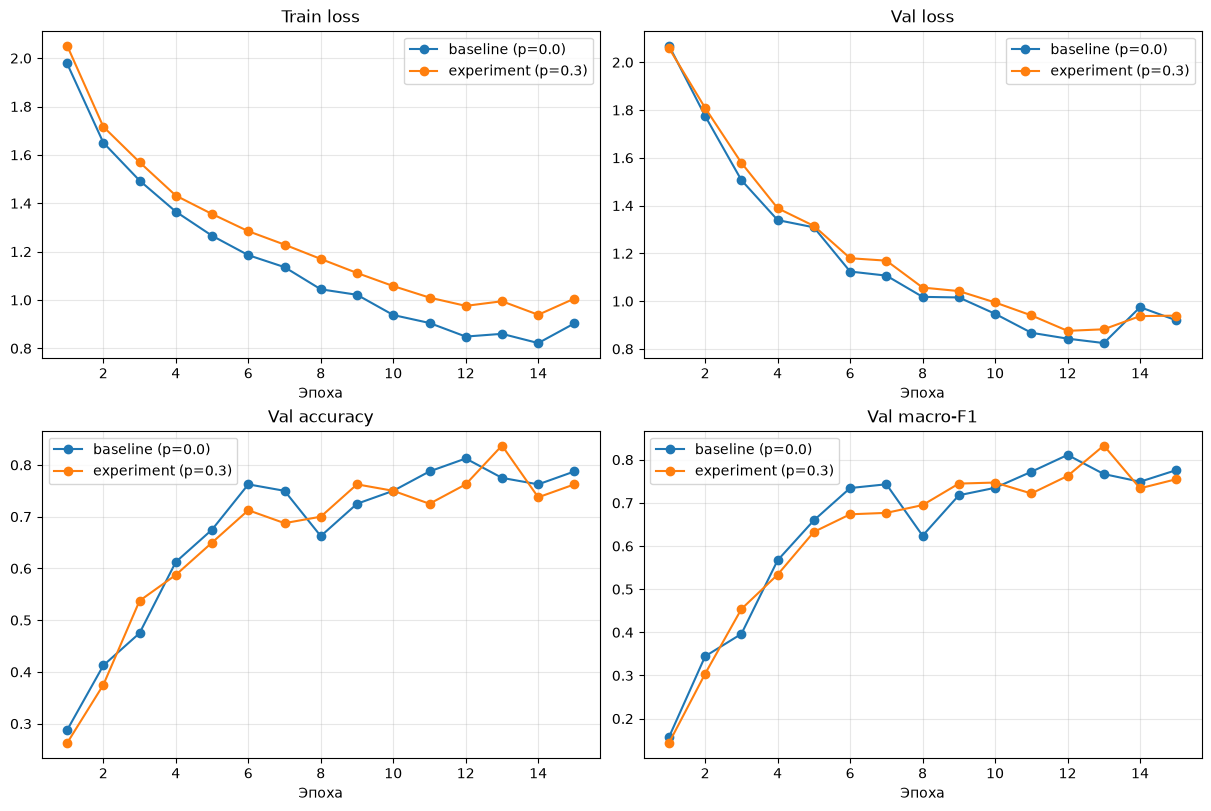

In [11]:
def plot_histories(histories, names):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
    metrics = [('train_loss', 'Train loss'), ('val_loss', 'Val loss'),
               ('val_accuracy', 'Val accuracy'), ('val_macro_f1', 'Val macro-F1')]
    for ax, (key, title) in zip(axes.ravel(), metrics):
        for hist, name in zip(histories, names):
            ax.plot(range(1, len(hist[key]) + 1), hist[key], marker='o', label=name)
        ax.set(title=title, xlabel='Эпоха')
        ax.grid(alpha=0.3)
        ax.legend()
    plt.show()

plot_histories([history_baseline, history_experiment],
               ['baseline (p=0.0)', 'experiment (p=0.3)'])

**Матрица ошибок базовой модели**

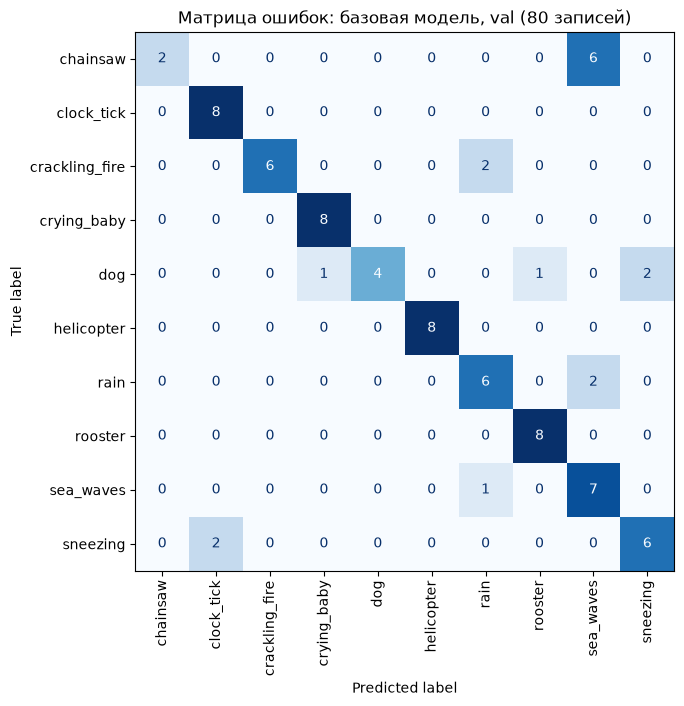

                precision    recall  f1-score   support

      chainsaw       1.00      0.25      0.40         8
    clock_tick       0.80      1.00      0.89         8
crackling_fire       1.00      0.75      0.86         8
   crying_baby       0.89      1.00      0.94         8
           dog       1.00      0.50      0.67         8
    helicopter       1.00      1.00      1.00         8
          rain       0.67      0.75      0.71         8
       rooster       0.89      1.00      0.94         8
     sea_waves       0.47      0.88      0.61         8
      sneezing       0.75      0.75      0.75         8

      accuracy                           0.79        80
     macro avg       0.85      0.79      0.78        80
  weighted avg       0.85      0.79      0.78        80



In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(val_baseline['y_true'], val_baseline['y_pred'],
                      labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=label_names).plot(
    ax=ax, cmap='Blues', values_format='d', xticks_rotation=90, colorbar=False)
ax.set_title('Матрица ошибок: базовая модель, val (80 записей)')
plt.show()

print(classification_report(val_baseline['y_true'], val_baseline['y_pred'],
                            labels=list(range(NUM_CLASSES)),
                            target_names=label_names, zero_division=0))

**Какие классы путаются**

In [13]:
errors = np.flatnonzero(val_baseline['y_true'] != val_baseline['y_pred'])
print(f'Ошибок: {len(errors)} из {len(val_baseline["y_true"])} '
      f'(верных {len(val_baseline["y_true"]) - len(errors)})')

pairs = {}
for i in errors:
    key = (label_names[int(val_baseline['y_true'][i])],
           label_names[int(val_baseline['y_pred'][i])])
    pairs[key] = pairs.get(key, 0) + 1
print('\nСамые частые путаницы (true → pred):')
for (t, p), cnt in sorted(pairs.items(), key=lambda kv: -kv[1]):
    print(f'  {t} → {p}: {cnt}')

Ошибок: 17 из 80 (верных 63)

Самые частые путаницы (true → pred):
  chainsaw → sea_waves: 6
  crackling_fire → rain: 2
  rain → sea_waves: 2
  sneezing → clock_tick: 2
  dog → sneezing: 2
  sea_waves → rain: 1
  dog → crying_baby: 1
  dog → rooster: 1


**Анализ ошибок базовой модели (17 ошибок из 80, accuracy 0.787, macro-F1 0.776).**

**Хорошо распознаются:** helicopter (F1 = 1.00), crying_baby и rooster (0.94), clock_tick (0.89), crackling_fire (0.86). У них характерная и стабильная структура: helicopter — ровный гул с гармониками и ритмичной модуляцией лопастей; crying_baby и rooster — тональные крики с выраженными гармониками; clock_tick — регулярные щелчки.

**Основные ошибки концентрируются в двух группах:**

1. **Непрерывные широкополосные звуки.** Самый частый переход — chainsaw → sea_waves (6 из 8 записей бензопилы!). Также rain → sea_waves (2), crackling_fire → rain (2), sea_waves → rain (1). Из-за этого chainsaw имеет recall 0.25 при precision 1.00, а sea_waves — precision 0.47 при recall 0.88: модель «сваливает» непонятные непрерывные шумы в sea_waves. Все эти классы заполняют энергией всю спектрограмму все 5 секунд, и различаются в основном *временной динамикой* (ровный рёв мотора с гармониками против медленных нарастаний прибоя) и тонкой частотной структурой.

2. **Короткие импульсные события.** dog распознан только наполовину (4 из 8): ошибки dog → sneezing (2), dog → crying_baby (1), dog → rooster (1). Также sneezing → clock_tick (2). Это классы, где событие занимает доли секунды из пяти.

**Вероятная архитектурная причина.** В сети используется глобальный average pooling (`AdaptiveAvgPool2d(1,1)`), который усредняет карту признаков по всему времени. Из-за этого:
- короткий лай длительностью ~0.3 с занимает около 6% кадров, и его энергия «размывается» усреднением — усреднённая спектрограмма записи с лайом определяется в основном фоном;
- теряется временной порядок и ритм, а именно он отличает ровный гул бензопилы от волнообразного прибоя и одиночный чих от периодических щелчков часов.

После трёх MaxPool и GAP модель опирается главным образом на усреднённый спектральный «облик» записи, а он у бензопилы и морских волн похож: энергия размазана по всем mel-каналам.

**Дополнительный фактор — мало данных:** по 32 обучающие записи на класс, при этом записи бензопилы сильно различаются (холостой ход против пиления, близко против издали). Модель могла не увидеть в train те варианты звучания, которые попались в val.

**Три val-записи: аудио + графики + true/pred**

Пример 1 (верный ответ).
5-151085-A-20.wav | true: crying_baby | pred: crying_baby | уверенность: 0.70


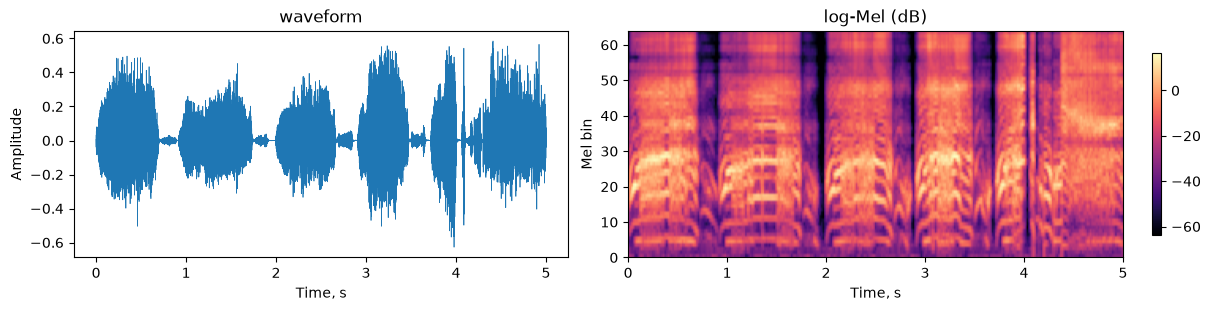

Пример 2 (верный ответ, другой класс).
5-177957-A-40.wav | true: helicopter | pred: helicopter | уверенность: 0.31


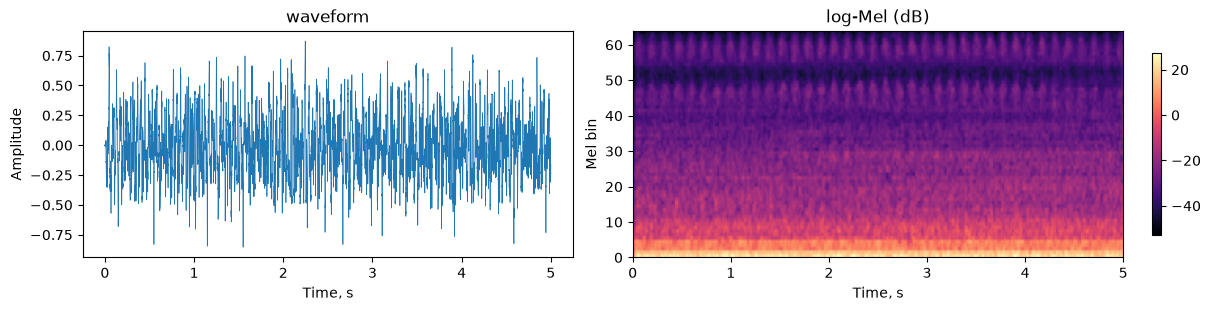

Пример 3 (разбор ошибки).
5-170338-A-41.wav | true: chainsaw | pred: sea_waves | уверенность: 0.49


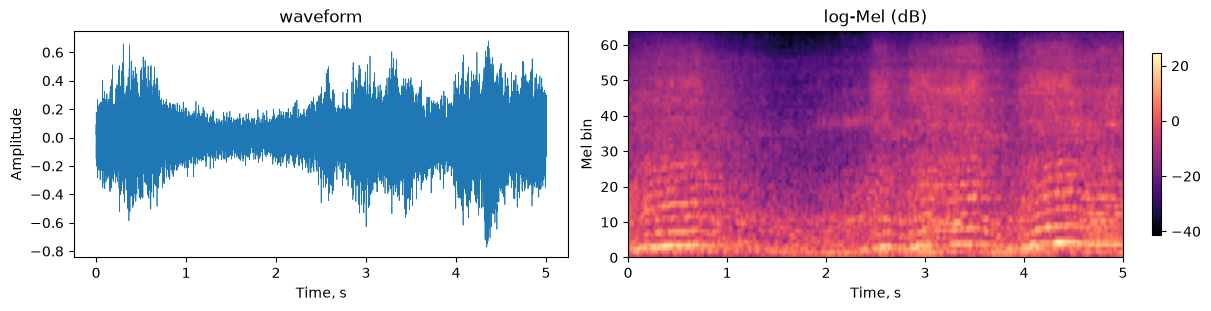

In [14]:
def show_val_example(i, val_result, title=''):
    row = esc10_df.iloc[int(val_idx[i])]
    true_name = label_names[int(val_result['y_true'][i])]
    pred_name = label_names[int(val_result['y_pred'][i])]
    conf = float(val_result['probs'][i].max())
    print(f'{title}\n{row["filename"]} | true: {true_name} | pred: {pred_name} | '
          f'уверенность: {conf:.2f}')
    wav = read_waveform(row['filename'])
    spec = waveform_to_logmel(wav)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3), constrained_layout=True)
    axes[0].plot(np.arange(len(wav)) / SAMPLE_RATE, wav, linewidth=0.5)
    axes[0].set(title='waveform', xlabel='Time, s', ylabel='Amplitude')
    im = axes[1].imshow(spec, origin='lower', aspect='auto', cmap='magma',
                        extent=(0, DURATION_S, 0, N_MELS))
    axes[1].set(title='log-Mel (dB)', xlabel='Time, s', ylabel='Mel bin')
    fig.colorbar(im, ax=axes[1], shrink=0.8)
    plt.show()
    display(Audio(data=wav, rate=SAMPLE_RATE))

correct_idx = np.flatnonzero(val_baseline['y_true'] == val_baseline['y_pred'])
error_idx = np.flatnonzero(val_baseline['y_true'] != val_baseline['y_pred'])
ex1 = int(correct_idx[0])
ex2 = int(correct_idx[val_baseline['y_true'][correct_idx] != val_baseline['y_true'][ex1]][0])
ex3 = int(error_idx[0]) if len(error_idx) else int(np.argmin(val_baseline['probs'].max(axis=1)))

show_val_example(ex1, val_baseline, 'Пример 1 (верный ответ).')
show_val_example(ex2, val_baseline, 'Пример 2 (верный ответ, другой класс).')
show_val_example(ex3, val_baseline, 'Пример 3 (разбор ошибки).')

**Сравнительная таблица**

In [15]:
comparison = pd.DataFrame([
    {'Запуск': 'Базовый', 'Изменённый фактор': '—', 'Dropout p': 0.0,
     'Эпох': EPOCHS, 'LR': LEARNING_RATE,
     'Train loss': history_baseline['train_loss'][-1], 'Val loss': val_baseline['loss'],
     'Val accuracy': val_baseline['accuracy'], 'Val macro-F1': val_baseline['macro_f1'],
     'Лучший val macro-F1': max(history_baseline['val_macro_f1'])},
    {'Запуск': 'Контрольный', 'Изменённый фактор': 'dropout p: 0.0 → 0.3',
     'Dropout p': DROPOUT_EXPERIMENT, 'Эпох': EPOCHS, 'LR': LEARNING_RATE,
     'Train loss': history_experiment['train_loss'][-1], 'Val loss': val_experiment['loss'],
     'Val accuracy': val_experiment['accuracy'], 'Val macro-F1': val_experiment['macro_f1'],
     'Лучший val macro-F1': max(history_experiment['val_macro_f1'])},
])
display(comparison.round(4))

,Запуск,Изменённый фактор,Dropout p,Эпох,LR,Train loss,Val loss,Val accuracy,Val macro-F1,Лучший val macro-F1
0,Базовый,—,0.0,15,0.001,0.9035,0.9198,0.7875,0.7760,0.8112
1,Контрольный,dropout p: 0.0 → 0.3,0.3,15,0.001,1.0059,0.9394,0.7625,0.7549,0.8329


**Сопоставление запусков.** Менялся ровно один фактор: вероятность dropout в голове сети (0.0 → 0.3). Архитектура, SEED=42, состав train/val, BATCH_SIZE=16, Adam, lr=1e-3 и 15 эпох — одинаковые в обоих запусках. У Dropout нет обучаемых параметров, поэтому при том же seed обе модели стартовали с одинаковых весов.

**Что показала базовая модель.** Train loss снизился с 1.978 до 0.904, val accuracy выросла с 0.287 до 0.787. При этом финальный val loss (0.920) почти равен train loss (0.904) — разрыв всего 0.016. Значит, **сильного переобучения нет**: сеть скорее недообучена, обе кривые на 15-й эпохе ещё не вышли на плато. Исходная гипотеза о том, что сеть «быстро запоминает train», не подтвердилась.

**Что дал dropout.** Финальный train loss вырос с 0.904 до 1.006 — регуляризация действительно мешает подгонке под обучающие данные. Val loss при этом 0.939, то есть *ниже* train loss; это ожидаемый эффект самой механики dropout (на train он активен и «ослабляет» сеть, на val выключен), а не доказательство лучшего обобщения.

**Итоговые метрики:** accuracy 0.787 → 0.762, macro-F1 0.776 → 0.755 — небольшое снижение. Но лучший по эпохам macro-F1 у dropout-версии выше: 0.833 (13-я эпоха) против 0.811 (12-я эпоха) у базовой.

**Почему вывод не может быть однозначным:** разница итоговых accuracy 0.787 − 0.762 — это всего 2 записи из 80. В val по 8 записей на класс, одна ошибка меняет recall класса на 12.5%. Кривые обоих запусков колеблются от эпохи к эпохе на ±0.05–0.08, что сопоставимо с самой разницей. Кроме того, обе модели к 15-й эпохе ещё не сошлись, поэтому сравнение по последнему значению ненадёжно.

**Итог: гипотеза подтвердилась частично.** Механизм регуляризации сработал (train loss выше, пик val macro-F1 выше), но устойчивого выигрыша итоговых метрик на этом разбиении не получено. Более того, диагностика показала, что основная проблема не в переобучении, а в недообученности и в потере временной информации из-за глобального усреднения — поэтому dropout и не мог дать ожидаемого прироста.

## 12. Итоговые выводы — `TODO`

Ответьте кратко и по существу:

- Удалось ли обучить базовую модель? Какие факты это подтверждают?
- Какие классы классифицируются хорошо, какие путаются, и чем это можно объяснить?
- Что изменилось во втором эксперименте? Подтвердилась ли гипотеза?
- Каковы ограничения результатов на 400 коротких записях?

**Перед сдачей:** сохраните ноутбук **с уже выполненными ячейками, результатами и графиками**. Не прикладывайте скачанные WAV, кэш `data/*.npz` и большие веса модели. Сдаётся только `solution.ipynb`.

## Итоговые выводы

**1. Базовую модель удалось обучить.**
Да. Train loss монотонно снизился с 1.978 до 0.904, val accuracy выросла с 0.287 (случайный уровень ~0.1) до 0.7875, val macro-F1 = 0.7760. Верно классифицированы 63 записи из 80. Программные проверки подтвердили, что веса изменились после обучения и что train loss убывает. Модель компактная — 24 170 параметров, обучение на CPU заняло ~17 секунд.

**2. Распознавание классов.**
Хорошо: helicopter (F1 = 1.00), crying_baby и rooster (0.94), clock_tick (0.89), crackling_fire (0.86) — у них выраженная и стабильная структура (гармоники крика, ритм лопастей, регулярные щелчки).
Плохо: chainsaw (F1 = 0.40, recall 0.25), sea_waves (0.61, precision 0.47), dog (0.67).
Ошибки концентрируются в двух группах: (а) непрерывные широкополосные звуки — chainsaw → sea_waves 6 раз, rain → sea_waves 2, crackling_fire → rain 2; (б) короткие импульсные события — dog → sneezing 2, dog → crying_baby 1, dog → rooster 1, sneezing → clock_tick 2.
Объяснение: глобальный average pooling усредняет признаки по времени, из-за чего теряется временная динамика (ровный рёв мотора против волнообразного прибоя) и «размывается» короткое событие — лай занимает малое количество кадров записи. Плюс мало данных: 32 обучающие записи на класс не покрывают все варианты звучания.

**3. Второй эксперимент.**
Менялся только dropout p: 0.0 → 0.3. Train loss вырос (0.904 → 1.006) — регуляризация работает. Итоговые метрики слегка снизились (accuracy 0.7875 → 0.7625, macro-F1 0.7760 → 0.7549), но лучший по эпохам macro-F1 оказался выше (0.8329 против 0.8112). Гипотеза подтвердилась частично: механизм сработал, устойчивого выигрыша нет. При этом сама предпосылка гипотезы (сильное переобучение) не подтвердилась — разрыв train/val у базовой модели всего 0.016, сеть недообучена. Разница в 2 записи из 80 лежит в пределах шума одного fold.

**4. Ограничения результатов.**
- 400 записей по 5 секунд, 32 train / 8 val на класс: одна ошибка меняет recall класса на 12.5%, метрики шумные.
- Один фиксированный fold (val = fold 5) без кросс-валидации: результат зависит от того, какие именно 8 записей каждого класса попали в валидацию.
- 15 эпох — обе модели не вышли на плато, сравнение по последней эпохе ненадёжно.
- Одна архитектура и один seed: нельзя отделить эффект фактора от случайности инициализации.
- Архитектурное ограничение: GAP по времени плохо подходит для коротких импульсных событий.